In [23]:
import pandas as pd
import numpy as np
import sklearn
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

print("\nEnvironment setup successful!")


Environment setup successful!


In [24]:
columns = (
    ['unit_number', 'time_in_cycles']
    + [f'op_setting_{i}' for i in range(1, 4)]
    + [f'sensor_{i}' for i in range(1, 22)]
)

In [25]:
DATA_PATH = "../data/"
# FD002
train_fd002 = pd.read_csv(DATA_PATH + "train_FD002.txt", sep=r"\s+", header=None, names=columns)
test_fd002 = pd.read_csv(DATA_PATH + "test_FD002.txt", sep=r"\s+", header=None, names=columns)
rul_fd002 = pd.read_csv(DATA_PATH + "RUL_FD002.txt", sep=r"\s+", header=None, names=["RUL"])

In [26]:
datasets = {
    "FD002 Train": train_fd002,
    "FD002 Test": test_fd002,
    "FD002 RUL": rul_fd002
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

FD002 Train: (53759, 26)
FD002 Test: (33991, 26)
FD002 RUL: (259, 1)


In [27]:
def validate_dataset(df, name):

    print(f"\n{'='*40}")
    print(f"Dataset: {name}")
    print(f"{'='*40}")

    print("Shape:", df.shape)
    print("Columns:", len(df.columns))
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

    print("Unique engines:", df['unit_number'].nunique()
          if 'unit_number' in df.columns else "N/A")

    print("Data types:")
    print(df.dtypes.value_counts())

for name, df in datasets.items():
    validate_dataset(df, name)


Dataset: FD002 Train
Shape: (53759, 26)
Columns: 26
Missing values: 0
Duplicate rows: 0
Unique engines: 260
Data types:
float64    22
int64       4
Name: count, dtype: int64

Dataset: FD002 Test
Shape: (33991, 26)
Columns: 26
Missing values: 0
Duplicate rows: 0
Unique engines: 259
Data types:
float64    22
int64       4
Name: count, dtype: int64

Dataset: FD002 RUL
Shape: (259, 1)
Columns: 1
Missing values: 0
Duplicate rows: 127
Unique engines: N/A
Data types:
int64    1
Name: count, dtype: int64


In [28]:
print("FD002 Test engines:", test_fd002['unit_number'].nunique())
print("FD002 RUL records:", len(rul_fd002))

FD002 Test engines: 259
FD002 RUL records: 259


In [29]:
# FD001 engine lifecycle
fd001_life = (
    train_fd002.groupby('unit_number')['time_in_cycles']
    .max()
)

In [30]:
sensor_columns = [
    col for col in train_fd002.columns
    if col.startswith('sensor_')
]
print("Total sensor columns:", len(sensor_columns))

Total sensor columns: 21


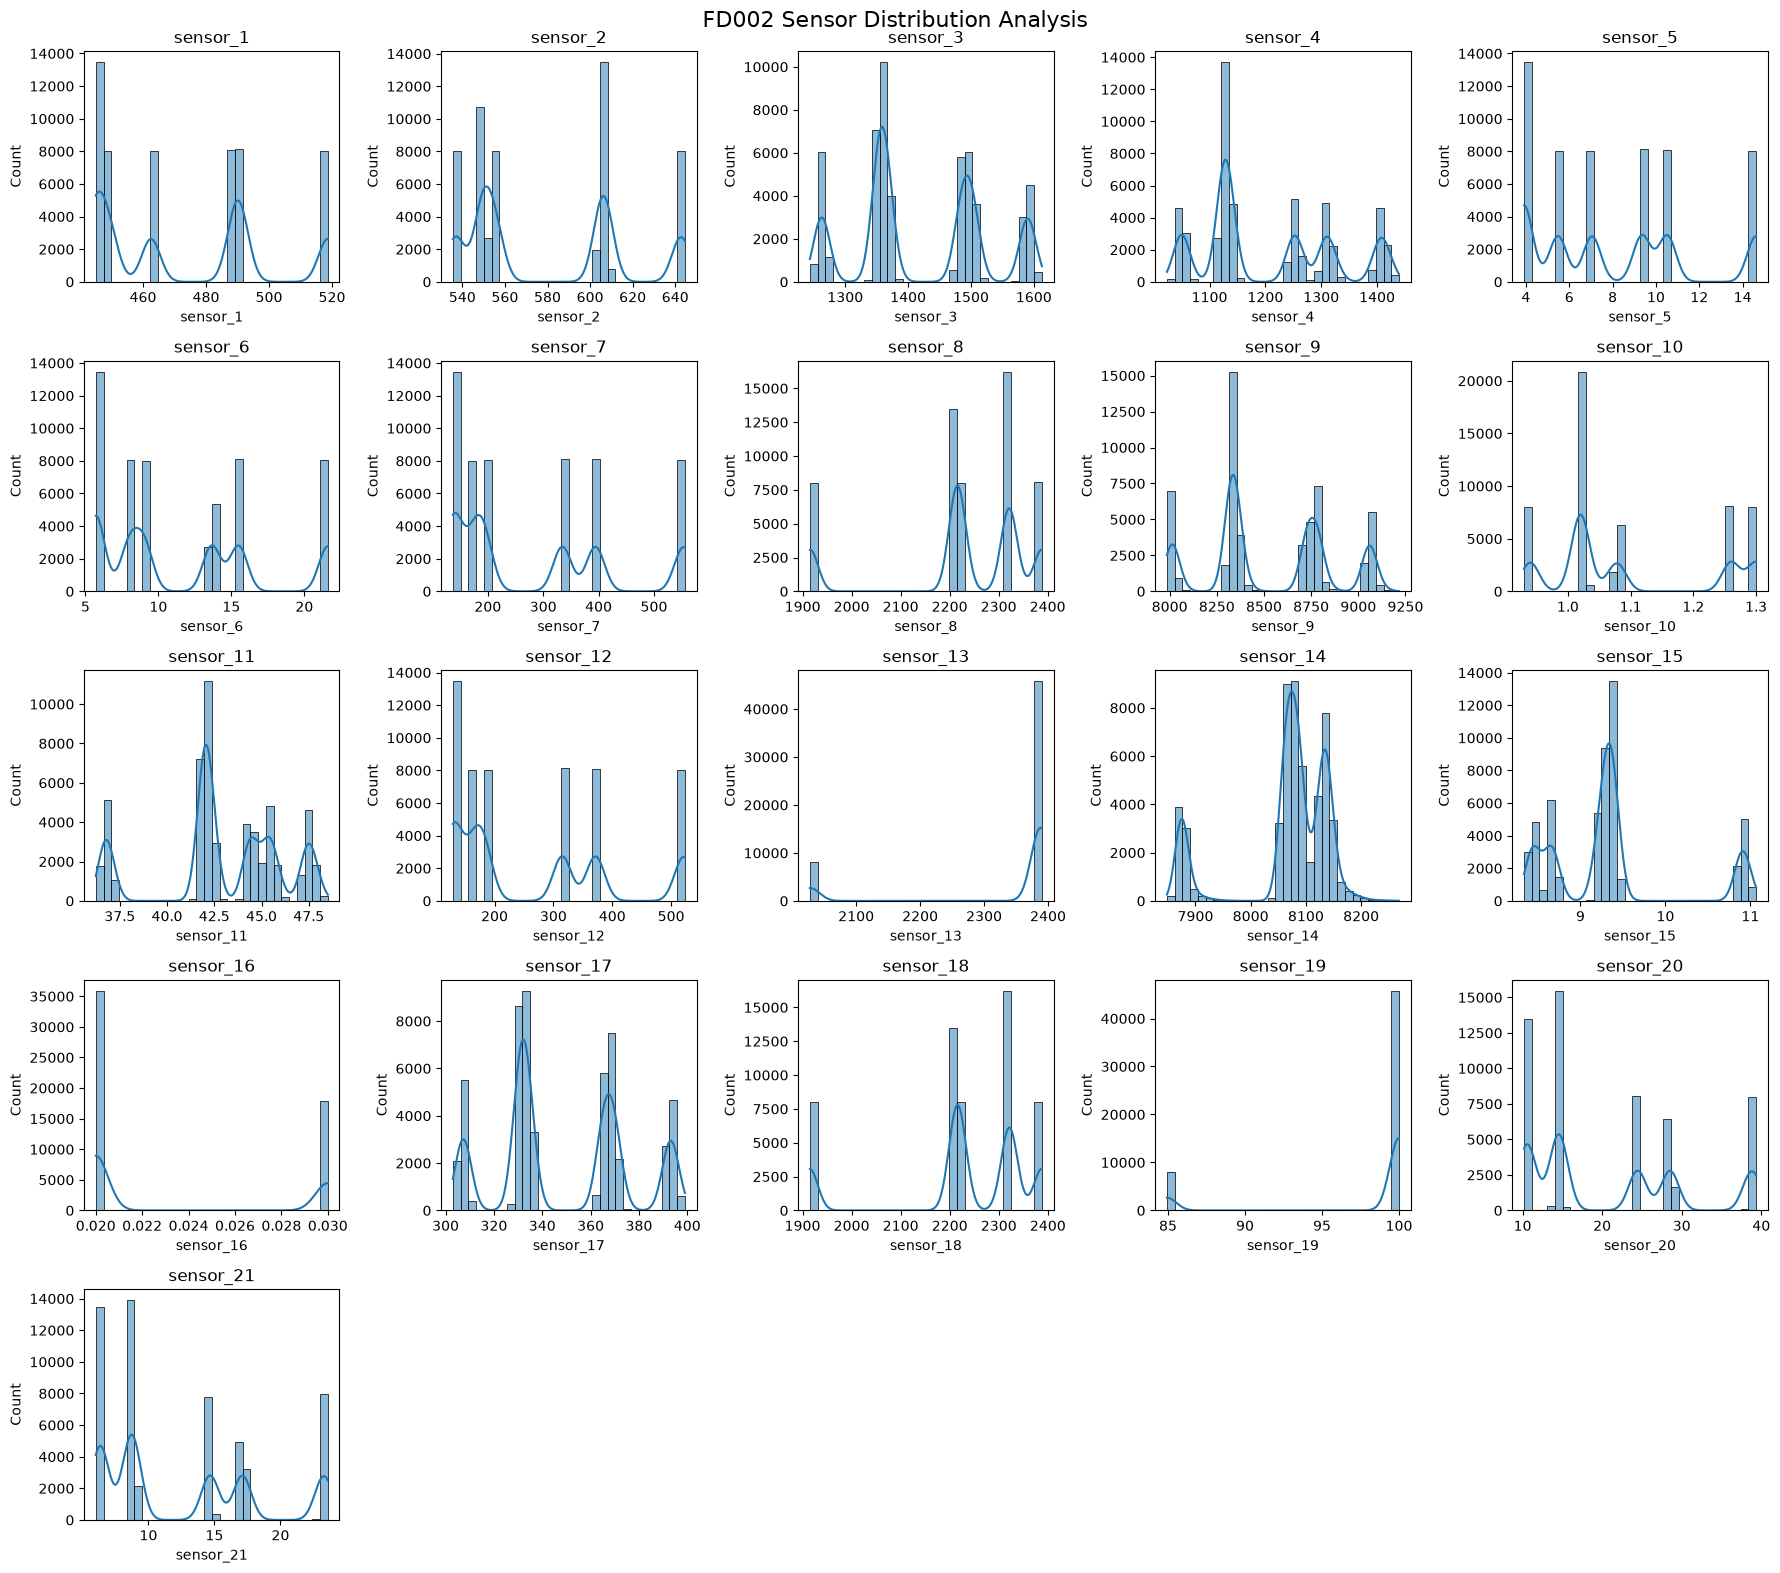

In [31]:
#FD002 sensor distributions
fig, axes = plt.subplots(5, 5, figsize=(18, 16))

for i, col in enumerate(sensor_columns):

    sns.histplot(
        data=train_fd002,
        x=col,
        kde=True,
        bins=30,
        ax=axes[i // 5, i % 5]
    )

    axes[i // 5, i % 5].set_title(col)

for i in range(len(sensor_columns), 25):
    axes[i // 5, i % 5].set_visible(False)

plt.suptitle(
    "FD002 Sensor Distribution Analysis",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [32]:
for name, df in {
    "FD002": train_fd002,
}.items():

    constant = [
        col for col in df.columns
        if df[col].nunique() <= 1
    ]

    print(f"{name} constant columns:")
    print(constant)

FD002 constant columns:
[]


In [33]:
# FD001 engine lifecycle
fd001_life = (
    train_fd002.groupby('unit_number')['time_in_cycles']
    .max()
)


In [34]:
fd002_life = (
    train_fd002.groupby('unit_number')['time_in_cycles'].max()
)

In [35]:
print(fd002_life.head(10))

unit_number
1     149
2     269
3     206
4     235
5     154
6     175
7     174
8     151
9     199
10    184
Name: time_in_cycles, dtype: int64


In [36]:
print("FD002 Engine Lifespan:")
print(fd002_life.describe())

FD002 Engine Lifespan:
count    260.000000
mean     206.765385
std       46.782198
min      128.000000
25%      174.000000
50%      199.000000
75%      230.250000
max      378.000000
Name: time_in_cycles, dtype: float64


In [37]:
# Analyze the data for a specific engine
engine_1 = train_fd002[
    train_fd002['unit_number'] == 1
]

engine_1.head()

,unit_number,time_in_cycles,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,...,183.06,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,...,130.42,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,...,164.22,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723
3,1,4,42.0077,0.8416,100.0,445.00,549.51,1354.03,1126.38,3.91,...,130.72,2387.61,8068.66,9.3528,0.02,329,2212,100.00,10.59,6.4701
4,1,5,25.0005,0.6203,60.0,462.54,537.07,1257.71,1047.93,7.05,...,164.31,2028.00,7861.23,10.8963,0.02,309,1915,84.93,14.13,8.5286


In [38]:
operating_settings = train_fd002[
    ['op_setting_1', 'op_setting_2', 'op_setting_3']
]

operating_settings.describe()

,op_setting_1,op_setting_2,op_setting_3
count,53759.000000,53759.000000,53759.000000
mean,23.998407,0.572056,94.046020
std,14.747376,0.310016,14.237735
min,0.000000,0.000000,60.000000
25%,10.004600,0.250700,100.000000
50%,25.001300,0.700000,100.000000
75%,41.998000,0.840000,100.000000
max,42.008000,0.842000,100.000000


In [39]:
unique_conditions = operating_settings.drop_duplicates()

print("Unique operating conditions:",
      len(unique_conditions))

unique_conditions.head(10)

Unique operating conditions: 9824


,op_setting_1,op_setting_2,op_setting_3
0,34.9983,0.8400,100.0
1,41.9982,0.8408,100.0
2,24.9988,0.6218,60.0
3,42.0077,0.8416,100.0
4,25.0005,0.6203,60.0
5,25.0045,0.6205,60.0
6,42.0043,0.8409,100.0
7,20.0020,0.7002,100.0
8,41.9995,0.8407,100.0
9,42.0011,0.8400,100.0


In [40]:
operating_columns = [
    'op_setting_1',
    'op_setting_2',
    'op_setting_3'
]

In [41]:
condition_groups = (
    train_fd002
    .assign(
        op_setting_1=train_fd002['op_setting_1'].round(0),
        op_setting_2=train_fd002['op_setting_2'].round(2)
    )
    .groupby(operating_columns)
    .size()
    .reset_index(name='record_count')
)

condition_groups

,op_setting_1,op_setting_2,op_setting_3,record_count
0,0.0,0.00,100.0,8044
1,10.0,0.25,100.0,8096
2,20.0,0.70,100.0,8122
3,25.0,0.62,60.0,8002
4,35.0,0.84,100.0,8037
5,42.0,0.84,100.0,13458


In [42]:
rounded_settings = train_fd002[operating_columns].copy()

rounded_settings['op_setting_1'] = rounded_settings['op_setting_1'].round(0)
rounded_settings['op_setting_2'] = rounded_settings['op_setting_2'].round(2)

train_fd002['operating_condition'] = pd.factorize(
    pd.MultiIndex.from_frame(rounded_settings)
)[0]

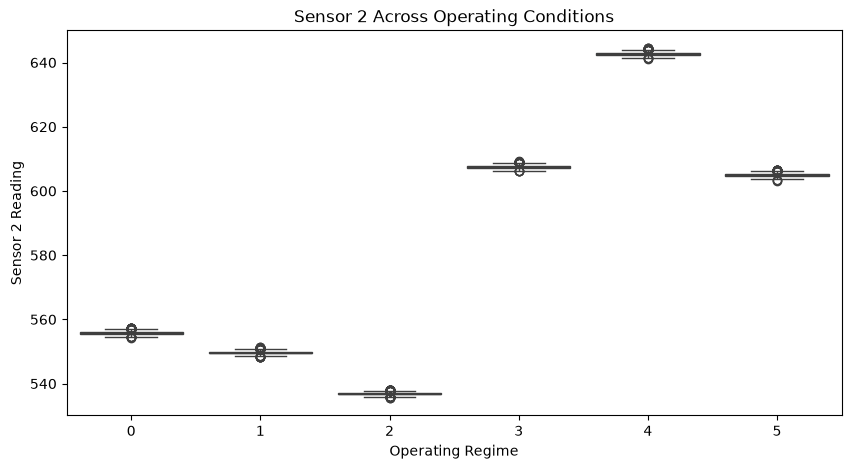

In [43]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train_fd002,
    x='operating_condition',
    y='sensor_2'
)

plt.title('Sensor 2 Across Operating Conditions')
plt.xlabel('Operating Regime')
plt.ylabel('Sensor 2 Reading')

plt.show()

In [44]:
sensor_means = train_fd002.groupby('operating_condition')[sensor_columns].mean()

display(sensor_means.round(2))

,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
operating_condition,,,,,,,,,,,,,,,,,,,,,
0,449.44,555.80,1366.71,1131.53,5.48,8.00,194.44,2223.04,8356.10,1.02,...,183.02,2388.14,8072.20,9.33,0.02,334.24,2223.0,100.00,14.83,8.90
1,445.00,549.70,1354.46,1127.80,3.91,5.72,138.63,2211.97,8327.89,1.02,...,130.55,2388.05,8089.44,9.38,0.02,331.07,2212.0,100.00,10.59,6.35
2,462.54,536.87,1262.68,1050.32,7.05,9.03,175.43,1915.42,8015.50,0.94,...,164.57,2028.31,7878.46,10.91,0.02,307.35,1915.0,84.93,14.26,8.56
3,491.19,607.56,1485.59,1253.12,9.35,13.66,334.50,2324.02,8729.77,1.08,...,314.87,2388.15,8065.91,9.23,0.02,365.38,2324.0,100.00,24.45,14.67
4,518.67,642.68,1590.42,1408.86,14.62,21.61,553.36,2388.10,9062.83,1.30,...,521.40,2388.10,8141.66,8.44,0.03,393.20,2388.0,100.00,38.82,23.29
5,489.05,604.91,1502.01,1311.25,10.52,15.49,394.32,2318.96,8785.44,1.26,...,371.45,2388.16,8135.13,8.66,0.03,369.70,2319.0,100.00,28.53,17.12


In [45]:
# Calculate the mean of each sensor for every regime
sensor_means = train_fd002.groupby(
    'operating_condition'
)[sensor_columns].mean()

# Calculate variation across operating regimes
sensor_variation = (
    sensor_means.max() - sensor_means.min()
).sort_values(ascending=False)

display(sensor_variation.to_frame(name='Mean_Range'))

,Mean_Range
sensor_9,1047.335250
sensor_18,473.000000
sensor_8,472.684705
sensor_7,414.730344
sensor_12,390.855119
sensor_13,359.847759
sensor_4,358.540021
sensor_3,327.736351
sensor_14,263.200914
sensor_2,105.813652


In [46]:
sensor_std = train_fd002.groupby(
    'operating_condition'
)[sensor_columns].std()

within_condition_std = sensor_std.mean().sort_values(
    ascending=False
)

display(within_condition_std.to_frame(name='Average_Within_Regime_STD'))

,Average_Within_Regime_STD
sensor_9,17.296189
sensor_14,15.440292
sensor_4,7.839283
sensor_3,5.687575
sensor_17,1.430415
sensor_7,0.584790
sensor_12,0.471193
sensor_2,0.443996
sensor_11,0.238597
sensor_13,0.199709


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16196\3276159456.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


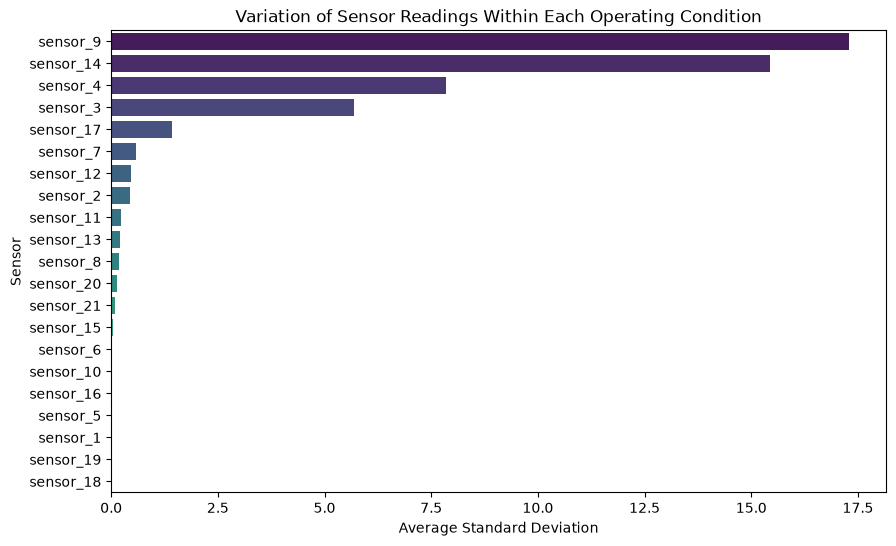

In [47]:
#horizontal bar plot for sensor variation
plt.figure(figsize=(10, 6))
sns.barplot(
    x=within_condition_std.values,
    y=within_condition_std.index,
    palette='viridis'
)
plt.title('Variation of Sensor Readings Within Each Operating Condition')
plt.xlabel('Average Standard Deviation')
plt.ylabel('Sensor')
plt.show()

In [48]:
# Variation between operating regimes
between_regime = (
    sensor_means.max() - sensor_means.min()
)

# Average variation within operating regimes
within_regime = sensor_std.mean()

# Compare both
variation_comparison = pd.DataFrame({
    'Between_Regime': between_regime,
    'Within_Regime': within_regime
})

variation_comparison['Ratio'] = (
    variation_comparison['Between_Regime'] /
    variation_comparison['Within_Regime'].replace(0, np.nan)
)

display(
    variation_comparison.sort_values(
        'Ratio', ascending=False
    ).round(3)
)

,Between_Regime,Within_Regime,Ratio
sensor_6,15.894,0.004,4429.997
sensor_8,472.685,0.189,2503.938
sensor_13,359.848,0.200,1801.863
sensor_12,390.855,0.471,829.501
sensor_7,414.730,0.585,709.196
sensor_10,0.360,0.001,246.995
sensor_2,105.814,0.444,238.321
sensor_21,16.939,0.078,216.775
sensor_20,28.231,0.132,214.469
sensor_15,2.472,0.039,63.658


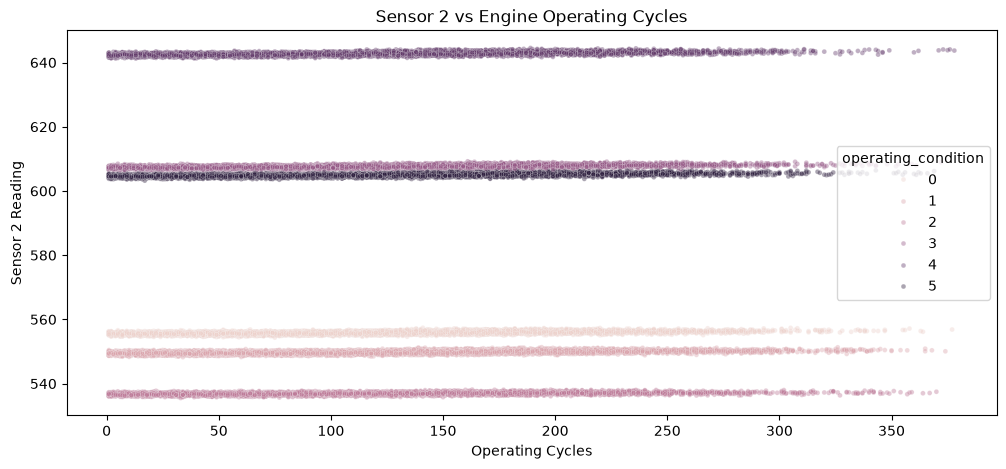

In [49]:
plt.figure(figsize=(12, 5))

sns.scatterplot(
    data=train_fd002,
    x='time_in_cycles',
    y='sensor_2',
    hue='operating_condition',
    alpha=0.4,
    s=12
)

plt.title('Sensor 2 vs Engine Operating Cycles')
plt.xlabel('Operating Cycles')
plt.ylabel('Sensor 2 Reading')
plt.show()

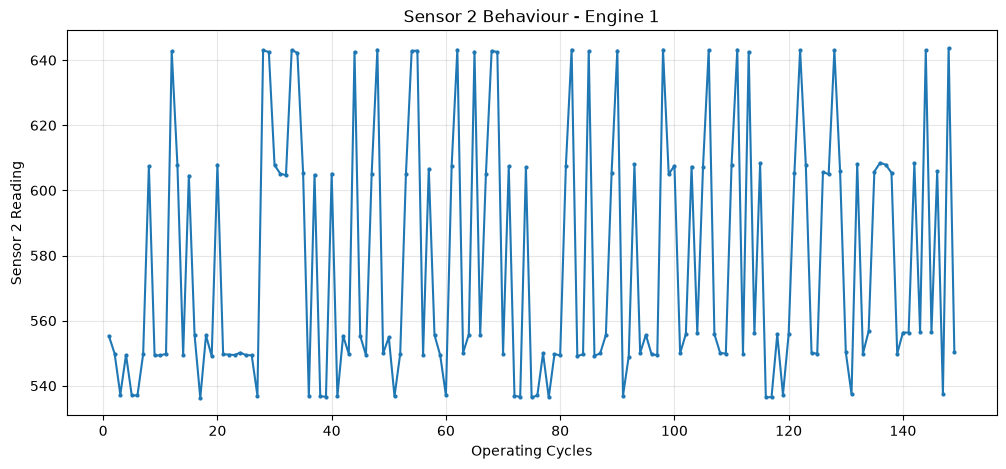

In [50]:
engine_id = 1

engine_data = train_fd002[
    train_fd002['unit_number'] == engine_id
]

plt.figure(figsize=(12, 5))

plt.plot(
    engine_data['time_in_cycles'],
    engine_data['sensor_2'],
    marker='.',
    markersize=4
)

plt.title(f'Sensor 2 Behaviour - Engine {engine_id}')
plt.xlabel('Operating Cycles')
plt.ylabel('Sensor 2 Reading')
plt.grid(alpha=0.3)
plt.show()

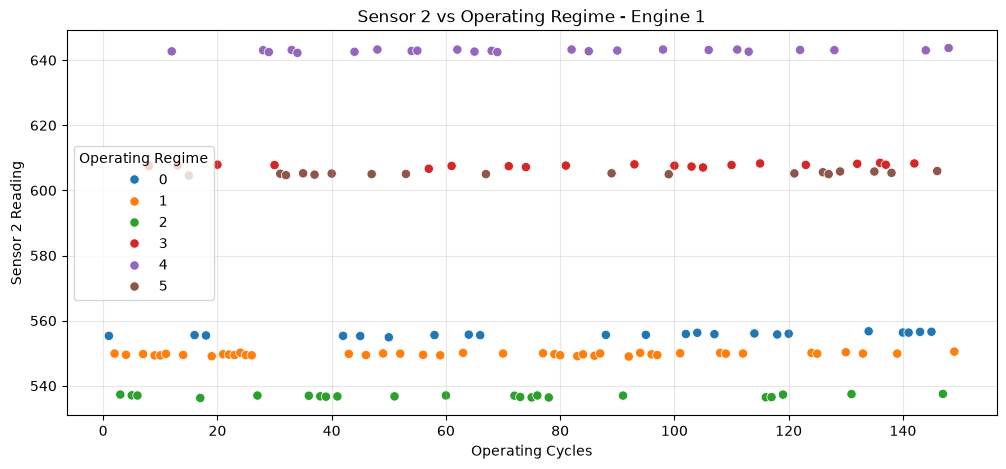

In [51]:
plt.figure(figsize=(12, 5))

sns.scatterplot(
    data=engine_data,
    x='time_in_cycles',
    y='sensor_2',
    hue='operating_condition',
    palette='tab10',
    s=45
)

plt.title('Sensor 2 vs Operating Regime - Engine 1')
plt.xlabel('Operating Cycles')
plt.ylabel('Sensor 2 Reading')
plt.legend(title='Operating Regime')
plt.grid(alpha=0.3)
plt.show()

In [52]:
display(
    train_fd002.groupby('operating_condition')['sensor_2']
    .agg(['mean', 'std', 'min', 'max'])
    .round(4)
)

,mean,std,min,max
operating_condition,,,,
0,555.7992,0.4395,554.32,557.39
1,549.7049,0.4329,548.25,551.35
2,536.8651,0.3581,535.53,538.15
3,607.5649,0.4631,606.11,609.23
4,642.6787,0.4959,641.24,644.52
5,604.9134,0.4745,603.21,606.45


In [53]:
# Calculate training statistics for Sensor 2
sensor2_stats = train_fd002.groupby(
    'operating_condition'
)['sensor_2'].agg(['mean', 'std'])

# Normalize training Sensor 2
train_fd002['sensor_2_normalized'] = (
    train_fd002['sensor_2']
    - train_fd002['operating_condition'].map(sensor2_stats['mean'])
) / train_fd002['operating_condition'].map(sensor2_stats['std'])

In [54]:
display(
    train_fd002[
        ['unit_number', 'time_in_cycles',
         'operating_condition', 'sensor_2',
         'sensor_2_normalized']
    ].head()
)

,unit_number,time_in_cycles,operating_condition,sensor_2,sensor_2_normalized
0,1,1,0,555.32,-1.090273
1,1,2,1,549.90,0.450777
2,1,3,2,537.31,1.242381
3,1,4,1,549.51,-0.450228
4,1,5,2,537.07,0.572229


In [55]:
normalized_check = train_fd002.groupby(
    'operating_condition'
)['sensor_2_normalized'].agg(['mean', 'std'])

display(normalized_check.round(4))

,mean,std
operating_condition,,
0,-0.0,1.0
1,-0.0,1.0
2,0.0,1.0
3,0.0,1.0
4,0.0,1.0
5,-0.0,1.0


In [56]:
selected_sensors = [
    'sensor_2', 'sensor_3', 'sensor_4',
    'sensor_6', 'sensor_7', 'sensor_8',
    'sensor_9', 'sensor_10', 'sensor_11',
    'sensor_12', 'sensor_13', 'sensor_14',
    'sensor_15', 'sensor_17', 'sensor_20'
]

In [57]:
condition_stats = train_fd002.groupby(
    'operating_condition'
)[selected_sensors].agg(['mean', 'std'])

display(condition_stats)

sensor_2               sensor_3               sensor_4  \
                           mean       std         mean       std         mean   
operating_condition                                                             
0                    555.799163  0.439489  1366.713352  5.615667  1131.530749   
1                    549.704881  0.432850  1354.463034  5.633500  1127.802495   
2                    536.865069  0.358128  1262.684786  5.280543  1050.320924   
3                    607.564851  0.463106  1485.587547  5.783238  1253.118492   
4                    642.678721  0.495905  1590.421137  6.022352  1408.860945   
5                    604.913381  0.474500  1502.012059  5.790149  1311.253127   

                                sensor_6              sensor_7            ...  \
                          std       mean       std        mean       std  ...   
operating_condition                                                       ...   
0                    7.401791   8.000296  0.001695  194.443407  0.476396  ...   
1                    7.637032   5.715840  0.004929  138.630382  0.439125  ...   
2                    6.808897   9.027761  0.004181  175.425952  0.447735  ...   
3                    7.793733  13.656623  0.004735  334.496711  0.606028  ...   
4                    8.936758  21.609831  0.001289  553.360726  0.868006  ...   
5                    8.457488  15.493286  0.004697  394.324910  0.671447  ...   

                       sensor_13              sensor_14             sensor_15  \
                            mean       std         mean        std       mean   
operating_condition                                                             
0                    2388.138173  0.299609  8072.199063  15.435011   9.332298   
1                    2388.052269  0.323314  8089.438359  16.478299   9.375055   
2                    2028.314200  0.277415  7878.461663  13.040321  10.913964   
3                    2388.154163  0.129583  8065.910277  15.125684   9.232689   
4                    2388.099434  0.070718  8141.662577  16.541648   8.442246   
5                    2388.161959  0.097613  8135.127500  16.020790   8.664625   

                                sensor_17            sensor_20            
                          std        mean       std       mean       std  
operating_condition                                                       
0                    0.038161  334.235038  1.404103  14.830771  0.113182  
1                    0.037516  331.066503  1.408724  10.586419  0.107921  
2                    0.043211  307.348163  1.292785  14.262839  0.112084  
3                    0.038959  365.384511  1.466289  24.454191  0.135061  
4                    0.036937  393.198533  1.521365  38.817484  0.177530  
5                    0.038185  369.699728  1.489226  28.526285  0.144014  

[6 rows x 30 columns]

In [58]:
for sensor in selected_sensors:

    means = condition_stats[(sensor, 'mean')]
    stds = condition_stats[(sensor, 'std')]

    train_fd002[f'{sensor}_normalized'] = (
        train_fd002[sensor]
        - train_fd002['operating_condition'].map(means)
    ) / train_fd002['operating_condition'].map(stds)

In [59]:
# Create a consistent mapping from training operating settings
condition_mapping = (
    train_fd002[
        operating_columns + ['operating_condition']
    ]
    .drop_duplicates()
)

# Round test operating settings in the same way as training
test_fd002['op_setting_1'] = test_fd002['op_setting_1'].round(0)
test_fd002['op_setting_2'] = test_fd002['op_setting_2'].round(2)

# Create lookup keys
condition_lookup = {
    tuple(row[operating_columns]): row['operating_condition']
    for _, row in condition_mapping.iterrows()
}

# Assign training regime labels to test data
test_fd002['operating_condition'] = test_fd002[
    operating_columns
].apply(
    lambda row: condition_lookup.get(tuple(row)),
    axis=1
)

# Check for unmatched regimes
print(test_fd002['operating_condition'].isna().sum())
print(test_fd002['operating_condition'].value_counts().sort_index())

0
operating_condition
0.0    5148
1.0    8483
2.0    5042
3.0    5063
4.0    5148
5.0    5107
Name: count, dtype: int64


In [60]:
print("Selected sensors:", selected_sensors)
print("Test columns:", test_fd002.columns.tolist())

print(
    "Operating condition missing:",
    test_fd002['operating_condition'].isna().sum()
)

Selected sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20']
Test columns: ['unit_number', 'time_in_cycles', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'operating_condition']
Operating condition missing: 0


In [61]:
for sensor in selected_sensors:

    means = condition_stats[(sensor, 'mean')]
    stds = condition_stats[(sensor, 'std')]

    test_fd002[f'{sensor}_normalized'] = (
        test_fd002[sensor]
        - test_fd002['operating_condition'].map(means)
    ) / test_fd002['operating_condition'].map(stds)

print("Normalization completed!")

print(
    "Sensor 2 normalized exists:",
    'sensor_2_normalized' in test_fd002.columns
)

display(
    test_fd002[
        ['sensor_2', 'operating_condition', 'sensor_2_normalized']
    ].head()
)

Normalization completed!
Sensor 2 normalized exists: True


,sensor_2,operating_condition,sensor_2_normalized
0,605.03,5.0,0.245773
1,607.82,3.0,0.550951
2,556.00,0.0,0.456980
3,550.17,1.0,1.074550
4,536.72,2.0,-0.405075


In [62]:
for sensor in selected_sensors:

    if sensor == 'sensor_2':
        continue

    means = condition_stats[(sensor, 'mean')]
    stds = condition_stats[(sensor, 'std')]

    test_fd002[f'{sensor}_normalized'] = (
        test_fd002[sensor]
        - test_fd002['operating_condition'].map(means)
    ) / test_fd002['operating_condition'].map(stds)

print("All selected test sensors normalized!")

All selected test sensors normalized!


In [63]:
normalized_columns = [
    f'{sensor}_normalized'
    for sensor in selected_sensors
]

print(
    "Missing normalized values:",
    test_fd002[normalized_columns].isna().sum().sum()
)

display(test_fd002[normalized_columns].head())

Missing normalized values: 5148


,sensor_2_normalized,sensor_3_normalized,sensor_4_normalized,sensor_6_normalized,sensor_7_normalized,sensor_8_normalized,sensor_9_normalized,sensor_10_normalized,sensor_11_normalized,sensor_12_normalized,sensor_13_normalized,sensor_14_normalized,sensor_15_normalized,sensor_17_normalized,sensor_20_normalized
0,0.245773,-0.836258,-0.740542,-0.699478,0.320338,0.016548,-1.185525,0.019252,0.483591,0.456818,0.184821,-1.312513,-0.445873,-0.469860,-0.738014
1,0.550951,-0.758666,-0.899247,0.713276,-0.225586,-0.564109,-0.962116,0.541740,-0.790840,0.897996,-0.263635,-0.849567,0.200482,-0.944228,-1.215678
2,0.456980,-1.359296,-0.428376,-0.174680,-1.875346,-1.329009,-0.936089,-0.201625,-0.792845,0.044505,-1.295598,-1.241273,0.390490,-0.879592,1.318488
3,1.074550,-0.847259,0.011458,-1.184711,0.249628,-1.306342,-0.779366,-0.158295,0.256357,-0.438851,-1.027696,-1.367760,0.560959,0.662654,-2.190665
4,-0.405075,-1.799964,0.054205,0.535612,0.723748,-1.203904,-1.302742,0.089076,-0.198464,-0.035423,-0.952366,-0.981698,-1.059079,-1.816360,0.420762


In [64]:
# Training normalization
for sensor in selected_sensors:

    means = condition_stats[(sensor, 'mean')]
    stds = condition_stats[(sensor, 'std')]

    train_fd002[f'{sensor}_normalized'] = (
        train_fd002[sensor]
        - train_fd002['operating_condition'].map(means)
    ) / train_fd002['operating_condition'].map(stds)


# Test normalization
for sensor in selected_sensors:

    means = condition_stats[(sensor, 'mean')]
    stds = condition_stats[(sensor, 'std')]

    test_fd002[f'{sensor}_normalized'] = (
        test_fd002[sensor]
        - test_fd002['operating_condition'].map(means)
    ) / test_fd002['operating_condition'].map(stds)

In [65]:
normalized_columns = [
    f'{sensor}_normalized'
    for sensor in selected_sensors
]

print("Training missing values:",
      train_fd002[normalized_columns].isna().sum().sum())

print("Testing missing values:",
      test_fd002[normalized_columns].isna().sum().sum())

Training missing values: 8044
Testing missing values: 5148


In [66]:
# Check missing values sensor by sensor
train_missing = train_fd002[
    [f'{s}_normalized' for s in selected_sensors]
].isna().sum()

test_missing = test_fd002[
    [f'{s}_normalized' for s in selected_sensors]
].isna().sum()

missing_report = pd.DataFrame({
    'Training_Missing': train_missing,
    'Testing_Missing': test_missing
})

display(missing_report)

,Training_Missing,Testing_Missing
sensor_2_normalized,0,0
sensor_3_normalized,0,0
sensor_4_normalized,0,0
sensor_6_normalized,0,0
sensor_7_normalized,0,0
sensor_8_normalized,0,0
sensor_9_normalized,0,0
sensor_10_normalized,8044,5148
sensor_11_normalized,0,0
sensor_12_normalized,0,0


In [67]:
print(condition_stats[('sensor_10', 'mean')])
print("\nStandard deviation:")
print(condition_stats[('sensor_10', 'std')])

operating_condition
0    1.020391
1    1.020244
2    0.939921
3    1.077731
4    1.300000
5    1.259996
Name: (sensor_10, mean), dtype: float64

Standard deviation:
operating_condition
0    0.001938
1    0.001544
2    0.000884
3    0.004189
4    0.000000
5    0.000192
Name: (sensor_10, std), dtype: float64


In [68]:
print("Training:")
print(
    train_fd002.groupby('operating_condition')['sensor_10_normalized']
    .apply(lambda x: x.isna().sum())
)

print("\nTesting:")
print(
    test_fd002.groupby('operating_condition')['sensor_10_normalized']
    .apply(lambda x: x.isna().sum())
)

Training:
operating_condition
0       0
1       0
2       0
3       0
4    8044
5       0
Name: sensor_10_normalized, dtype: int64

Testing:
operating_condition
0.0       0
1.0       0
2.0       0
3.0       0
4.0    5148
5.0       0
Name: sensor_10_normalized, dtype: int64


In [69]:
normalized_sensors = [
    sensor for sensor in selected_sensors
    if sensor != 'sensor_10'
]

normalized_columns = [
    f'{sensor}_normalized'
    for sensor in normalized_sensors
]

In [70]:
print("Normalized sensors:", len(normalized_columns))

print("Training missing values:",
      train_fd002[normalized_columns].isna().sum().sum())

print("Testing missing values:",
      test_fd002[normalized_columns].isna().sum().sum())

print("Original sensor_10 available:",
      'sensor_10' in train_fd002.columns)

Normalized sensors: 14
Training missing values: 0
Testing missing values: 0
Original sensor_10 available: True


In [71]:
# Find the last operating cycle for each engine
max_cycles = train_fd002.groupby('unit_number')['time_in_cycles'].max()

# Map the maximum cycle to each record
train_fd002['RUL'] = (
    train_fd002['unit_number'].map(max_cycles)
    - train_fd002['time_in_cycles']
)

print(train_fd002[['unit_number', 'time_in_cycles', 'RUL']].head())

   unit_number  time_in_cycles  RUL
0            1               1  148
1            1               2  147
2            1               3  146
3            1               4  145
4            1               5  144


In [72]:
print("RUL missing values:", train_fd002['RUL'].isna().sum())
print("Minimum RUL:", train_fd002['RUL'].min())
print("Maximum RUL:", train_fd002['RUL'].max())

RUL missing values: 0
Minimum RUL: 0
Maximum RUL: 377


In [73]:
RUL_CAP = 125

train_fd002['RUL_capped'] = train_fd002['RUL'].clip(upper=RUL_CAP)

print(train_fd002[['RUL', 'RUL_capped']].head(10))

   RUL  RUL_capped
0  148         125
1  147         125
2  146         125
3  145         125
4  144         125
5  143         125
6  142         125
7  141         125
8  140         125
9  139         125


In [74]:
print("Original maximum RUL:", train_fd002['RUL'].max())
print("Capped maximum RUL:", train_fd002['RUL_capped'].max())

print("\nCapped records:")
print((train_fd002['RUL'] > RUL_CAP).sum())

Original maximum RUL: 377
Capped maximum RUL: 125

Capped records:
20999


In [75]:
# Check whether RUL was calculated using each engine's final training cycle
max_cycles = train_fd002.groupby('unit_number')['time_in_cycles'].max()

expected_rul = (
    train_fd002['unit_number'].map(max_cycles)
    - train_fd002['time_in_cycles']
)

print("RUL calculation matches:",
      train_fd002['RUL'].equals(expected_rul))

print("Negative RUL records:",
      (train_fd002['RUL'] < 0).sum())

print("Maximum RUL:",
      train_fd002['RUL'].max())

RUL calculation matches: True
Negative RUL records: 0
Maximum RUL: 377


In [76]:
train_engines = set(train_fd002['unit_number'].unique())
test_engines = set(test_fd002['unit_number'].unique())

print("Common engine IDs:", len(train_engines & test_engines))
print("Training engines:", len(train_engines))
print("Testing engines:", len(test_engines))

Common engine IDs: 259
Training engines: 260
Testing engines: 259


In [77]:
print("Training engine ID range:")
print(train_fd002['unit_number'].min(),
      train_fd002['unit_number'].max())

print("\nTesting engine ID range:")
print(test_fd002['unit_number'].min(),
      test_fd002['unit_number'].max())

print("\nFirst 10 training IDs:")
print(sorted(train_engines)[:10])

print("\nFirst 10 testing IDs:")
print(sorted(test_engines)[:10])

print("\nCommon IDs:")
print(sorted(train_engines & test_engines)[:20])

Training engine ID range:
1 260

Testing engine ID range:
1 259

First 10 training IDs:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

First 10 testing IDs:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

Common IDs:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


In [78]:
print("Are train and test the same object?",
      train_fd002 is test_fd002)

print("Training shape:", train_fd002.shape)
print("Testing shape:", test_fd002.shape)

print("Training duplicate engine-cycle records:",
      train_fd002.duplicated(
          ['unit_number', 'time_in_cycles']
      ).sum())

print("Testing duplicate engine-cycle records:",
      test_fd002.duplicated(
          ['unit_number', 'time_in_cycles']
      ).sum())

Are train and test the same object? False
Training shape: (53759, 44)
Testing shape: (33991, 42)
Training duplicate engine-cycle records: 0
Testing duplicate engine-cycle records: 0


In [79]:
print("Test engines:", test_fd002['unit_number'].nunique())

print("RUL file shape:", rul_fd002.shape)

print(rul_fd002.head())

Test engines: 259
RUL file shape: (259, 1)
   RUL
0   18
1   79
2  106
3  110
4   15


In [80]:
# Get the final observation for each test engine
test_last_cycle = (
    test_fd002
    .sort_values('time_in_cycles')
    .groupby('unit_number')
    .tail(1)
    .sort_values('unit_number')
    .reset_index(drop=True)
)

print("Final test records:", test_last_cycle.shape)
print(test_last_cycle[
    ['unit_number', 'time_in_cycles']
].head())

Final test records: (259, 42)
   unit_number  time_in_cycles
0            1             258
1            2              55
2            3             165
3            4              86
4            5             148


In [84]:
test_last_cycle = test_last_cycle.sort_values(
    'unit_number'
).copy()

test_last_cycle['RUL'] = rul_fd002['RUL'].values

In [85]:
print("Missing RUL:", test_last_cycle['RUL'].isna().sum())
print("RUL minimum:", test_last_cycle['RUL'].min())
print("RUL maximum:", test_last_cycle['RUL'].max())

print(test_last_cycle[['unit_number', 'RUL']].head())

Missing RUL: 0
RUL minimum: 6
RUL maximum: 194
   unit_number  RUL
0            1   18
1            2   79
2            3  106
3            4  110
4            5   15


In [86]:
from sklearn.model_selection import GroupShuffleSplit

# Group split based on engine IDs
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train_fd002,
        groups=train_fd002['unit_number']
    )
)

train_data = train_fd002.iloc[train_idx].copy()
val_data = train_fd002.iloc[val_idx].copy()

In [87]:
train_engines = set(train_data['unit_number'].unique())
val_engines = set(val_data['unit_number'].unique())

print("Training records:", train_data.shape)
print("Validation records:", val_data.shape)

print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))

print("Common engines:",
      len(train_engines & val_engines))

Training records: (43464, 44)
Validation records: (10295, 44)
Training engines: 208
Validation engines: 52
Common engines: 0


In [88]:
print("Training RUL range:")
print(train_data['RUL_capped'].min(),
      train_data['RUL_capped'].max())

print("\nValidation RUL range:")
print(val_data['RUL_capped'].min(),
      val_data['RUL_capped'].max())

Training RUL range:
0 125

Validation RUL range:
0 125


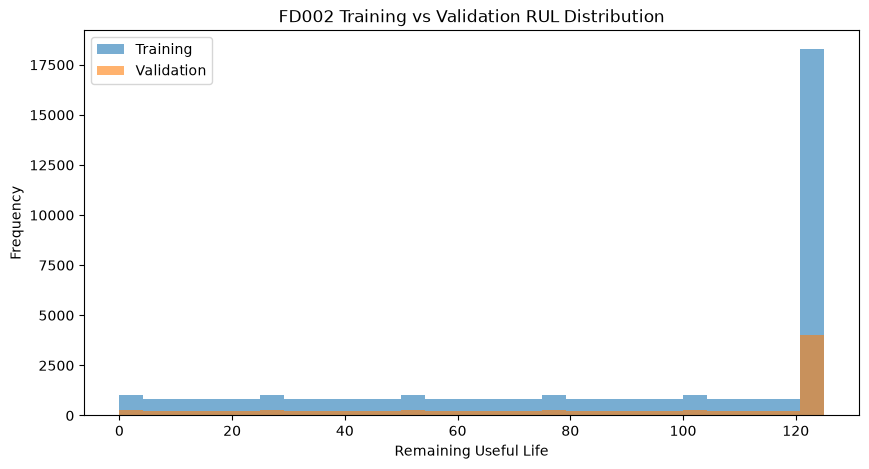

In [89]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    train_data['RUL_capped'],
    bins=30,
    alpha=0.6,
    label='Training'
)

plt.hist(
    val_data['RUL_capped'],
    bins=30,
    alpha=0.6,
    label='Validation'
)

plt.xlabel('Remaining Useful Life')
plt.ylabel('Frequency')
plt.title('FD002 Training vs Validation RUL Distribution')
plt.legend()
plt.show()

In [124]:
# Validation predictions
val_predictions = best_model.predict(X_val_normalized)

# Final-cycle test predictions
X_test_final = test_last_cycle[normalized_features]

test_predictions = best_model.predict(X_test_final)

# Actual test RUL
y_test_final = test_last_cycle['RUL']

In [125]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Validation metrics
val_mae = mean_absolute_error(y_val, val_predictions)
val_rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
val_r2 = r2_score(y_val, val_predictions)
val_nasa = nasa_score(y_val, val_predictions)

# Test metrics
test_mae = mean_absolute_error(y_test_final, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test_final, test_predictions))
test_r2 = r2_score(y_test_final, test_predictions)
test_nasa = nasa_score(y_test_final, test_predictions)

In [128]:
comparison = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R2 Score', 'NASA Score'],
    'Validation': [
        val_mae,
        val_rmse,
        val_r2,
        val_nasa
    ],
    'Test': [
        test_mae,
        test_rmse,
        test_r2,
        test_nasa
    ]
})

display(comparison.round(4))

,Metric,Validation,Test
0,MAE,14.2713,20.7504
1,RMSE,19.5785,29.4203
2,R2 Score,0.7804,0.7007
3,NASA Score,155278.8549,11903.2575


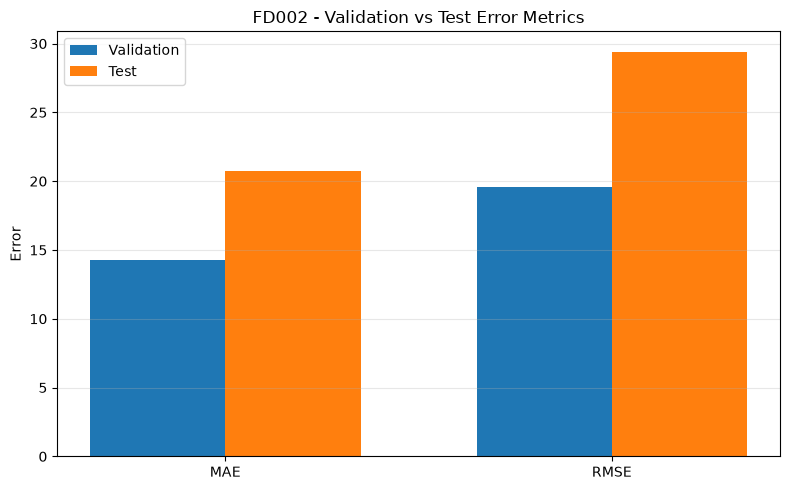

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['MAE', 'RMSE']
validation_values = [val_mae, val_rmse]
test_values = [test_mae, test_rmse]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, validation_values, width, label='Validation')
plt.bar(x + width/2, test_values, width, label='Test')

plt.xticks(x, metrics)
plt.ylabel('Error')
plt.title('FD002 - Validation vs Test Error Metrics')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

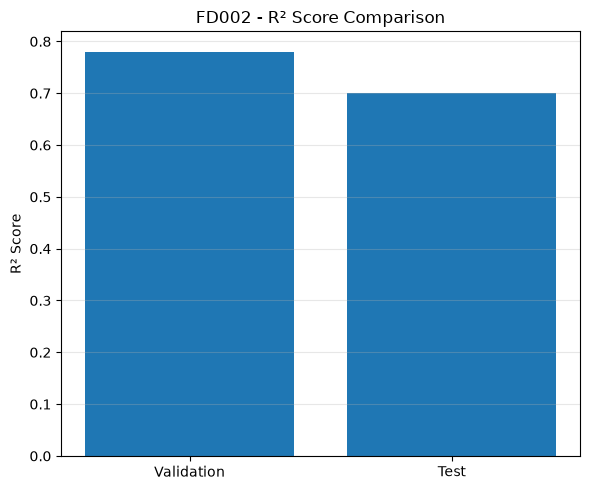

In [130]:
plt.figure(figsize=(6, 5))

plt.bar(
    ['Validation', 'Test'],
    [val_r2, test_r2]
)

plt.ylabel('R² Score')
plt.title('FD002 - R² Score Comparison')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [90]:
# Baseline features
baseline_features = (
    [f'sensor_{i}' for i in range(1, 22)]
    + operating_columns
)

# Normalized features
normalized_features = (
    normalized_columns
    + ['sensor_10']
    + operating_columns
)

print("Baseline feature count:", len(baseline_features))
print("Normalized feature count:", len(normalized_features))

Baseline feature count: 24
Normalized feature count: 18


In [91]:
# Target
y_train = train_data['RUL_capped']
y_val = val_data['RUL_capped']

# Baseline feature matrices
X_train_baseline = train_data[baseline_features]
X_val_baseline = val_data[baseline_features]

# Normalized feature matrices
X_train_normalized = train_data[normalized_features]
X_val_normalized = val_data[normalized_features]

print("Baseline training:", X_train_baseline.shape)
print("Baseline validation:", X_val_baseline.shape)

print("Normalized training:", X_train_normalized.shape)
print("Normalized validation:", X_val_normalized.shape)

Baseline training: (43464, 24)
Baseline validation: (10295, 24)
Normalized training: (43464, 18)
Normalized validation: (10295, 18)


In [92]:
print("Baseline training missing:",
      X_train_baseline.isna().sum().sum())

print("Normalized training missing:",
      X_train_normalized.isna().sum().sum())

print("Baseline validation missing:",
      X_val_baseline.isna().sum().sum())

print("Normalized validation missing:",
      X_val_normalized.isna().sum().sum())

Baseline training missing: 0
Normalized training missing: 0
Baseline validation missing: 0
Normalized validation missing: 0


In [93]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
xgb_baseline = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    eval_metric='mae',
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=50
)

In [94]:
xgb_baseline.fit(
    X_train_baseline,
    y_train,
    eval_set=[(X_val_baseline, y_val)],
    verbose=100
)

[0]	validation_0-mae:35.85495
[100]	validation_0-mae:15.00505
[200]	validation_0-mae:14.45255
[300]	validation_0-mae:14.35877
[400]	validation_0-mae:14.30253
[500]	validation_0-mae:14.29898
[507]	validation_0-mae:14.29792


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'mae'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [95]:
y_pred_baseline = xgb_baseline.predict(X_val_baseline)

In [96]:
mae = mean_absolute_error(y_val, y_pred_baseline)

rmse = np.sqrt(mean_squared_error(y_val, y_pred_baseline))

r2 = r2_score(y_val, y_pred_baseline)

print("FD002 Baseline XGBoost Results")
print("--------------------------------")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")
print(f"Best Iteration: {xgb_baseline.best_iteration}")

FD002 Baseline XGBoost Results
--------------------------------
MAE  : 14.2887
RMSE : 19.6743
R2   : 0.7783
Best Iteration: 457


In [97]:
def nasa_score(y_true, y_pred):
    errors = np.array(y_pred) - np.array(y_true)

    scores = np.where(
        errors < 0,
        np.exp(-errors / 13) - 1,
        np.exp(errors / 10) - 1
    )

    return np.sum(scores)


baseline_nasa = nasa_score(y_val, y_pred_baseline)

print(f"Baseline NASA Score: {baseline_nasa:.4f}")

Baseline NASA Score: 169944.9132


In [98]:
baseline_results = {
    'Model': 'Baseline XGBoost',
    'MAE': mae,
    'RMSE': rmse,
    'R2': r2,
    'NASA Score': baseline_nasa,
    'Best Iteration': xgb_baseline.best_iteration
}

results = [baseline_results]

In [99]:
X_train_normalized = train_data[normalized_features]
X_val_normalized = val_data[normalized_features]

y_train = train_data['RUL_capped']
y_val = val_data['RUL_capped']

print("Training:", X_train_normalized.shape)
print("Validation:", X_val_normalized.shape)

Training: (43464, 18)
Validation: (10295, 18)


In [100]:
xgb_normalized = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    eval_metric='mae',
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=50
)

In [101]:
xgb_normalized.fit(
    X_train_normalized,
    y_train,
    eval_set=[(X_val_normalized, y_val)],
    verbose=100
)

[0]	validation_0-mae:35.65544
[100]	validation_0-mae:14.35147
[200]	validation_0-mae:14.17719
[243]	validation_0-mae:14.17954


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'mae'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [102]:
# Generate predictions
y_pred_normalized = xgb_normalized.predict(X_val_normalized)

# Calculate metrics
normalized_mae = mean_absolute_error(
    y_val, y_pred_normalized
)

normalized_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred_normalized)
)

normalized_r2 = r2_score(
    y_val, y_pred_normalized
)

normalized_nasa = nasa_score(
    y_val, y_pred_normalized
)

print("FD002 Normalized XGBoost Results")
print("--------------------------------")
print(f"MAE  : {normalized_mae:.4f}")
print(f"RMSE : {normalized_rmse:.4f}")
print(f"R2   : {normalized_r2:.4f}")
print(f"NASA Score : {normalized_nasa:.4f}")
print(f"Best Iteration : {xgb_normalized.best_iteration}")

FD002 Normalized XGBoost Results
--------------------------------
MAE  : 14.1708
RMSE : 19.5724
R2   : 0.7806
NASA Score : 165027.3662
Best Iteration : 193


In [103]:
normalized_results = {
    'Model': 'Normalized XGBoost',
    'MAE': normalized_mae,
    'RMSE': normalized_rmse,
    'R2': normalized_r2,
    'NASA Score': normalized_nasa,
    'Best Iteration': xgb_normalized.best_iteration
}

results.append(normalized_results)

comparison_df = pd.DataFrame(results)

display(comparison_df)

,Model,MAE,RMSE,R2,NASA Score,Best Iteration
0,Baseline XGBoost,14.288723,19.674349,0.778279,169944.913171,457
1,Normalized XGBoost,14.170751,19.572423,0.780570,165027.366199,193


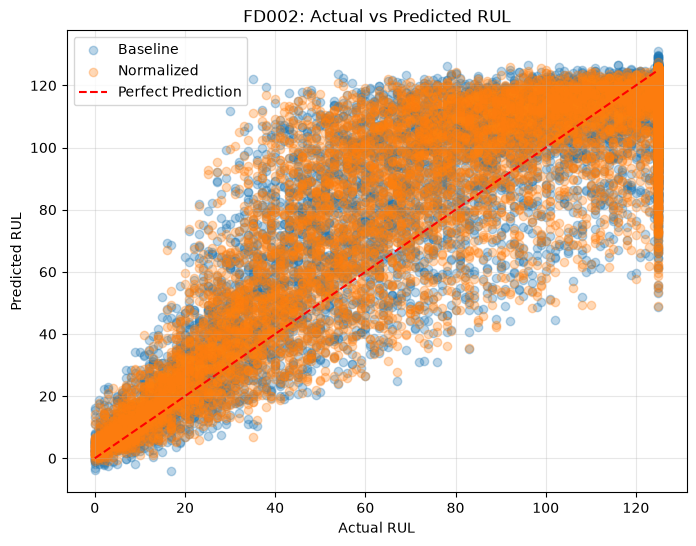

In [104]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    y_pred_baseline,
    alpha=0.3,
    label='Baseline'
)

plt.scatter(
    y_val,
    y_pred_normalized,
    alpha=0.3,
    label='Normalized'
)

plt.plot(
    [0, 125],
    [0, 125],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Actual RUL')
plt.ylabel('Predicted RUL')
plt.title('FD002: Actual vs Predicted RUL')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [105]:
import numpy as np

def nasa_score(y_true, y_pred):
    errors = np.asarray(y_pred) - np.asarray(y_true)

    scores = np.where(
        errors < 0,
        np.exp(-errors / 13) - 1,
        np.exp(errors / 10) - 1
    )

    return np.sum(scores)

In [106]:
from sklearn.model_selection import ParameterSampler

param_grid = {
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'min_child_weight': [1, 3, 5, 7],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'reg_alpha': [0, 0.01, 0.1],
    'reg_lambda': [1, 5, 10]
}

parameter_combinations = list(
    ParameterSampler(
        param_grid,
        n_iter=30,
        random_state=42
    )
)

print("Total combinations:", len(parameter_combinations))

Total combinations: 30


In [107]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.


In [108]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
from tqdm.auto import tqdm

tuning_results = []

for i, params in enumerate(
    tqdm(parameter_combinations)
):

    model = XGBRegressor(
        n_estimators=500,
        objective='reg:squarederror',
        eval_metric='mae',
        random_state=42,
        n_jobs=-1,
        **params
    )

    model.fit(
        X_train_normalized,
        y_train,
        verbose=False
    )

    predictions = model.predict(X_val_normalized)

    score = nasa_score(y_val, predictions)
    mae_value = mean_absolute_error(y_val, predictions)

    tuning_results.append({
        'Trial': i + 1,
        'NASA Score': score,
        'MAE': mae_value,
        'Parameters': params
    })

print("Hyperparameter search completed!")

  0%|          | 0/30 [00:00<?, ?it/s]

Hyperparameter search completed!


In [109]:
tuning_df = pd.DataFrame(tuning_results)

print("Total models evaluated:", len(tuning_df))
display(tuning_df.head())

Total models evaluated: 30


,Trial,NASA Score,MAE,Parameters
0,1,161565.762083,14.166818,"{'subsample': 0.9, 'reg_lambda': 5, 'reg_alpha..."
1,2,173937.581099,14.126139,"{'subsample': 0.9, 'reg_lambda': 10, 'reg_alph..."
2,3,167534.759069,14.130977,"{'subsample': 0.7, 'reg_lambda': 10, 'reg_alph..."
3,4,165033.686911,14.139209,"{'subsample': 0.8, 'reg_lambda': 10, 'reg_alph..."
4,5,189631.643421,14.269913,"{'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha..."


In [110]:
tuning_df = tuning_df.sort_values(
    by='NASA Score',
    ascending=True
).reset_index(drop=True)

display(tuning_df.head(10))

,Trial,NASA Score,MAE,Parameters
0,11,153042.023314,14.897599,"{'subsample': 0.8, 'reg_lambda': 10, 'reg_alph..."
1,26,154281.966975,14.209451,"{'subsample': 0.9, 'reg_lambda': 5, 'reg_alpha..."
2,17,155420.881028,14.578438,"{'subsample': 0.8, 'reg_lambda': 5, 'reg_alpha..."
3,20,158592.973674,14.446384,"{'subsample': 0.7, 'reg_lambda': 10, 'reg_alph..."
4,22,159061.167641,14.437713,"{'subsample': 0.7, 'reg_lambda': 5, 'reg_alpha..."
5,18,159319.658901,14.196248,"{'subsample': 0.9, 'reg_lambda': 1, 'reg_alpha..."
6,28,159913.133079,14.190571,"{'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha..."
7,27,160513.526497,14.440936,"{'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha..."
8,9,161173.162879,14.270731,"{'subsample': 0.8, 'reg_lambda': 10, 'reg_alph..."
9,1,161565.762083,14.166818,"{'subsample': 0.9, 'reg_lambda': 5, 'reg_alpha..."


In [111]:
best_trial = tuning_df.iloc[0]

best_params = best_trial['Parameters']
best_nasa = best_trial['NASA Score']

print("Best Parameters:")
print(best_params)

print("\nBest NASA Score:", best_nasa)

print("\nBaseline NASA Score:", baseline_nasa)

improvement = (
    (baseline_nasa - best_nasa) / baseline_nasa
) * 100

print(f"\nNASA Score Improvement: {improvement:.2f}%")

Best Parameters:
{'subsample': 0.8, 'reg_lambda': 10, 'reg_alpha': 0.1, 'min_child_weight': 7, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.9}

Best NASA Score: 153042.02331384586

Baseline NASA Score: 169944.91317091338

NASA Score Improvement: 9.95%


In [112]:
from xgboost.callback import EarlyStopping

best_model = XGBRegressor(
    n_estimators=2000,
    objective='reg:squarederror',
    eval_metric='mae',
    random_state=42,
    n_jobs=-1,
    **best_params,
    callbacks=[
        EarlyStopping(
            rounds=100,
            metric_name='mae',
            data_name='validation_0',
            save_best=True
        )
    ]
)

In [113]:
best_model.fit(
    X_train_normalized,
    y_train,
    eval_set=[(X_val_normalized, y_val)],
    verbose=100
)

[0]	validation_0-mae:36.63879
[100]	validation_0-mae:23.16787
[200]	validation_0-mae:18.18327
[300]	validation_0-mae:16.20066
[400]	validation_0-mae:15.31553
[500]	validation_0-mae:14.89509
[600]	validation_0-mae:14.69640
[700]	validation_0-mae:14.60952
[800]	validation_0-mae:14.54667
[900]	validation_0-mae:14.50920
[1000]	validation_0-mae:14.46921
[1100]	validation_0-mae:14.43266
[1200]	validation_0-mae:14.40485
[1300]	validation_0-mae:14.38119
[1400]	validation_0-mae:14.35730
[1500]	validation_0-mae:14.33766
[1600]	validation_0-mae:14.32095
[1700]	validation_0-mae:14.30959
[1800]	validation_0-mae:14.29368
[1900]	validation_0-mae:14.28188
[1999]	validation_0-mae:14.27184


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",[<xgboost.call...00165CF4D7610>]
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.9
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'mae'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [114]:
y_pred_tuned = best_model.predict(X_val_normalized)

tuned_mae = mean_absolute_error(y_val, y_pred_tuned)
tuned_rmse = np.sqrt(mean_squared_error(y_val, y_pred_tuned))
tuned_r2 = r2_score(y_val, y_pred_tuned)
tuned_nasa = nasa_score(y_val, y_pred_tuned)

print(f"MAE          : {tuned_mae:.4f}")
print(f"RMSE         : {tuned_rmse:.4f}")
print(f"R2           : {tuned_r2:.4f}")
print(f"NASA Score   : {tuned_nasa:.4f}")
print(best_model.get_booster().attributes())

MAE          : 14.2713
RMSE         : 19.5785
R2           : 0.7804
NASA Score   : 155278.8549
{'best_iteration': '1986', 'best_score': '14.27128084423821'}


In [115]:
print("Booster attributes:")
print(best_model.get_booster().attributes())

print(
    "Boosting rounds:",
    best_model.get_booster().num_boosted_rounds()
)

print("Best iteration:", best_model.best_iteration)

Booster attributes:
{'best_iteration': '1986', 'best_score': '14.27128084423821'}
Boosting rounds: 1987
Best iteration: 1986


In [116]:
import pandas as pd
import numpy as np

comparison_df = pd.DataFrame({
    'Model': [
        'Baseline',
        'Normalized',
        'Tuned (500 Trees)',
        'Tuned (Early Stopping)'
    ],
    'MAE': [
        14.2887,
        14.1708,
        np.nan,
        14.2713
    ],
    'RMSE': [
        19.6743,
        19.5724,
        np.nan,
        19.5785
    ],
    'R2 Score': [
        0.7783,
        0.7806,
        np.nan,
        0.7804
    ],
    'NASA Score': [
        169944.91,
        165027.37,
        153042.02,
        155278.85
    ]
})

comparison_df

,Model,MAE,RMSE,R2 Score,NASA Score
0,Baseline,14.2887,19.6743,0.7783,169944.91
1,Normalized,14.1708,19.5724,0.7806,165027.37
2,Tuned (500 Trees),NaN,NaN,NaN,153042.02
3,Tuned (Early Stopping),14.2713,19.5785,0.7804,155278.85


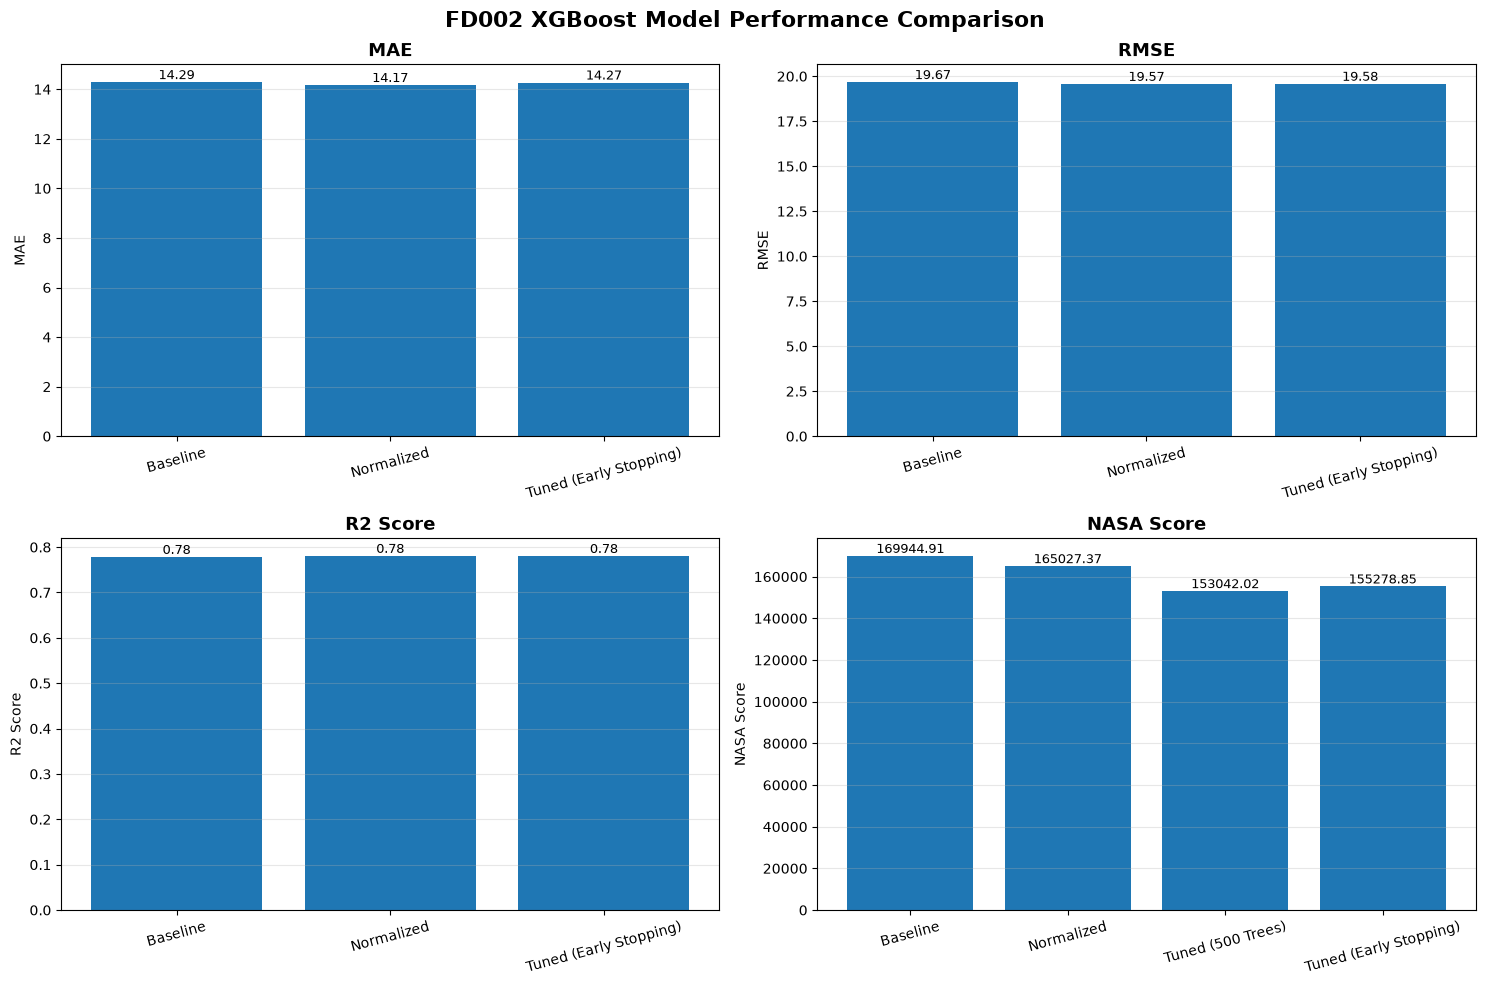

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['MAE', 'RMSE', 'R2 Score', 'NASA Score']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, metric in zip(axes, metrics):

    plot_data = comparison_df.dropna(subset=[metric])

    bars = ax.bar(
        plot_data['Model'],
        plot_data[metric]
    )

    feature
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', alpha=0.3)

    for bar in bars:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f'{value:.2f}',
            ha='center',
            va='bottom',
            fontsize=9
        )

fig.suptitle(
    'FD002 XGBoost Model Performance Comparison',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [134]:
#adding new features 5-cycle change
trend_source_columns = [
    col for col in normalized_features
    if col not in operating_columns
]

print("Selected sensors:")
print(trend_source_columns)

print("Total sensors:", len(trend_source_columns))

Selected sensors:
['sensor_2_normalized', 'sensor_3_normalized', 'sensor_4_normalized', 'sensor_6_normalized', 'sensor_7_normalized', 'sensor_8_normalized', 'sensor_9_normalized', 'sensor_11_normalized', 'sensor_12_normalized', 'sensor_13_normalized', 'sensor_14_normalized', 'sensor_15_normalized', 'sensor_17_normalized', 'sensor_20_normalized', 'sensor_10']
Total sensors: 15


In [138]:
def add_time_series_features(df, sensor_columns):

    df = df.sort_values(
        ['unit_number', 'time_in_cycles']
    ).copy()

    new_columns = []

    for col in sensor_columns:

        # 1. Lag feature (5 cycles)
        lag_col = f'{col}_lag_5'

        df[lag_col] = (
            df.groupby('unit_number')[col]
            .shift(5)
        )

        # 2. Rolling mean (5 cycles)
        mean_col = f'{col}_rolling_mean_5'

        df[mean_col] = (
            df.groupby('unit_number')[col]
            .transform(
                lambda s: s.rolling(
                    window=5,
                    min_periods=5
                ).mean()
            )
        )

        new_columns.extend([lag_col, mean_col])

    return df, new_columns

In [139]:
# Training data
train_data, trend_columns = add_time_series_features(
    train_data,
    trend_source_columns
)

# Validation data
val_data, _ = add_time_series_features(
    val_data,
    trend_source_columns
)

# Complete test data
test_fd002, _ = add_time_series_features(
    test_fd002,
    trend_source_columns
)

print("New features created:", len(trend_columns))
print("Training shape:", train_data.shape)
print("Validation shape:", val_data.shape)
print("Test shape:", test_fd002.shape)

New features created: 30
Training shape: (43464, 104)
Validation shape: (10295, 104)
Test shape: (33991, 102)


In [140]:
# Check missing values in new features
print("Training missing values:")
print(train_data[trend_columns].isnull().sum().sum())

print("\nValidation missing values:")
print(val_data[trend_columns].isnull().sum().sum())

print("\nTest missing values:")
print(test_fd002[trend_columns].isnull().sum().sum())

Training missing values:
28080

Validation missing values:
7020

Test missing values:
34965


In [141]:
train_data = train_data.groupby(
    'unit_number',
    group_keys=False
).apply(
    lambda group: group.iloc[5:]
).reset_index(drop=True)

val_data = val_data.groupby(
    'unit_number',
    group_keys=False
).apply(
    lambda group: group.iloc[5:]
).reset_index(drop=True)

In [142]:
print("Training missing:", train_data[trend_columns].isnull().sum().sum())
print("Validation missing:", val_data[trend_columns].isnull().sum().sum())

Training missing: 0
Validation missing: 0


In [143]:
enhanced_features = normalized_features + trend_columns

X_train_enhanced = train_data[enhanced_features]
X_val_enhanced = val_data[enhanced_features]

y_train_enhanced = train_data['RUL_capped']
y_val_enhanced = val_data['RUL_capped']

print("Baseline features:", len(normalized_features))
print("New features:", len(trend_columns))
print("Enhanced features:", len(enhanced_features))

print("Training shape:", X_train_enhanced.shape)
print("Validation shape:", X_val_enhanced.shape)

Baseline features: 18
New features: 30
Enhanced features: 48
Training shape: (42424, 48)
Validation shape: (10035, 48)


In [144]:
from xgboost import XGBRegressor
from xgboost.callback import EarlyStopping

enhanced_model = XGBRegressor(
    n_estimators=2000,
    objective='reg:squarederror',
    eval_metric='mae',
    random_state=42,
    n_jobs=-1,
    **best_params,
    callbacks=[
        EarlyStopping(
            rounds=100,
            metric_name='mae',
            data_name='validation_0',
            save_best=True
        )
    ]
)

enhanced_model.fit(
    X_train_enhanced,
    y_train_enhanced,
    eval_set=[(X_val_enhanced, y_val_enhanced)],
    verbose=False
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",[<xgboost.call...00165C90EF950>]
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.9
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'mae'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [145]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Predictions
y_pred_enhanced = enhanced_model.predict(X_val_enhanced)

# Metrics
enhanced_mae = mean_absolute_error(
    y_val_enhanced, y_pred_enhanced
)

enhanced_rmse = np.sqrt(
    mean_squared_error(y_val_enhanced, y_pred_enhanced)
)

enhanced_r2 = r2_score(
    y_val_enhanced, y_pred_enhanced
)

enhanced_nasa = nasa_score(
    y_val_enhanced, y_pred_enhanced
)

print("Enhanced Model Validation Results")
print("---------------------------------")
print("MAE:", enhanced_mae)
print("RMSE:", enhanced_rmse)
print("R2 Score:", enhanced_r2)
print("NASA Score:", enhanced_nasa)
print("Best Iteration:", enhanced_model.best_iteration)

Enhanced Model Validation Results
---------------------------------
MAE: 13.403478622436523
RMSE: 18.564730834489126
R2 Score: 0.8029430508613586
NASA Score: 129745.64367672574
Best Iteration: 1999


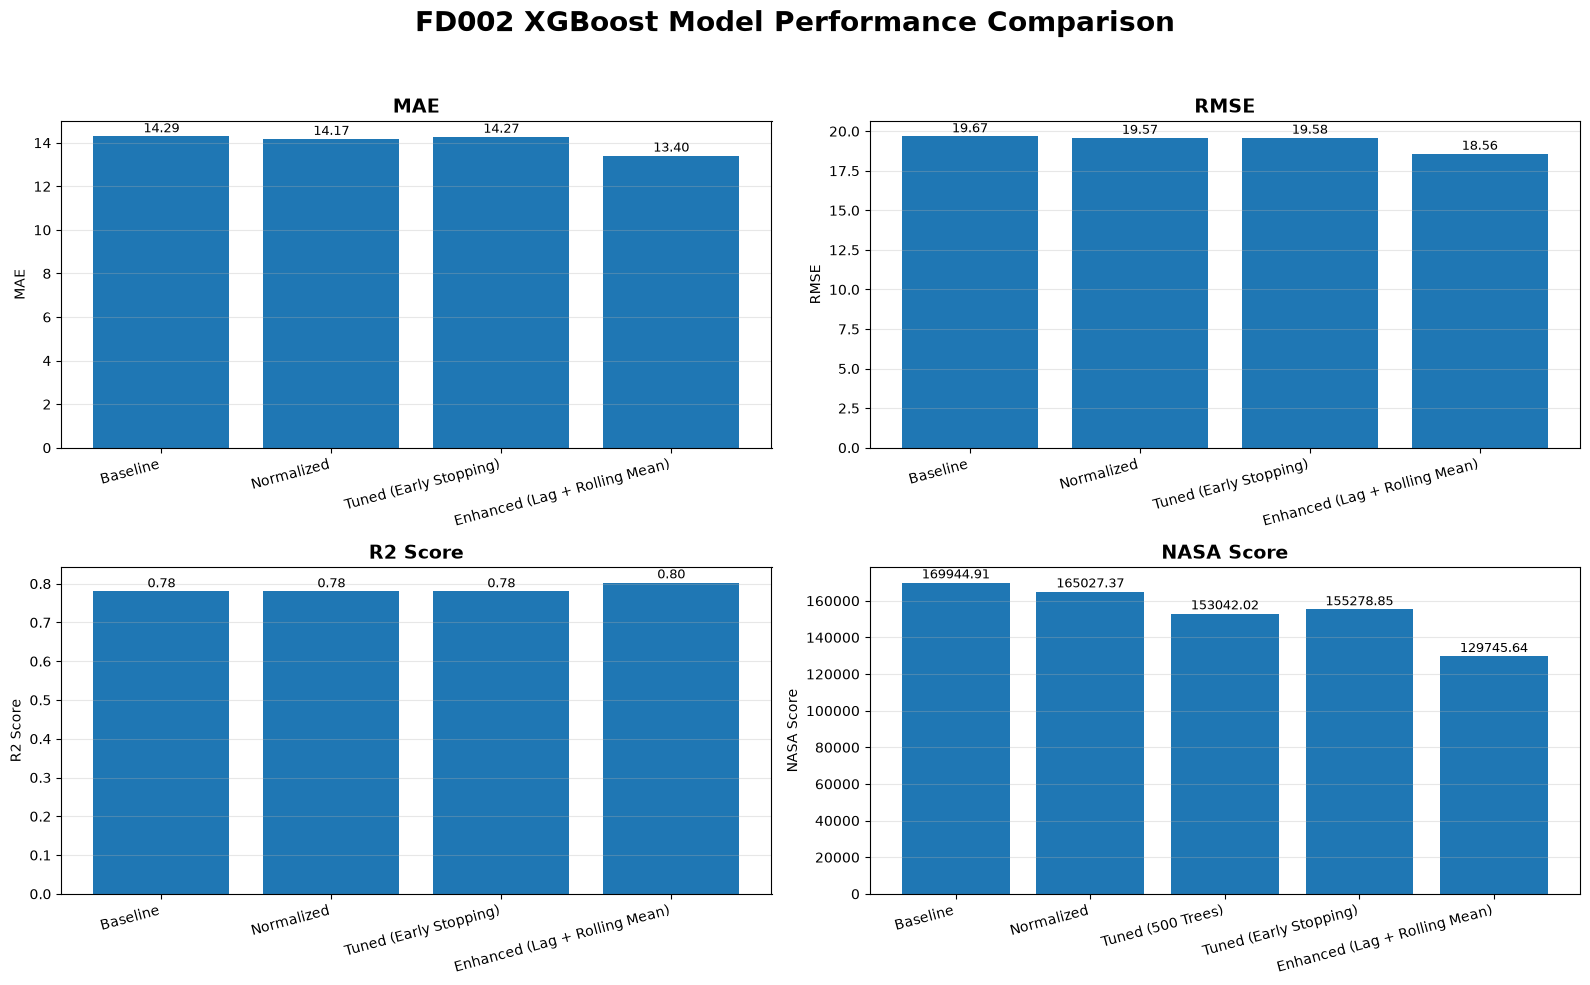

In [147]:
import matplotlib.pyplot as plt
import numpy as np

# Model names
models = [
    'Baseline',
    'Normalized',
    'Tuned (500 Trees)',
    'Tuned (Early Stopping)',
    'Enhanced (Lag + Rolling Mean)'
]

# Performance metrics
mae = [14.29, 14.17, 14.27, 13.4035]
rmse = [19.67, 19.57, 19.58, 18.5647]
r2 = [0.78, 0.78, 0.78, 0.8029]

nasa = [
    169944.91,
    165027.37,
    153042.02,
    155278.85,
    129745.64
]

# Separate model labels
models_first_three = [
    'Baseline',
    'Normalized',
    'Tuned (Early Stopping)',
    'Enhanced (Lag + Rolling Mean)'
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

fig.suptitle(
    'FD002 XGBoost Model Performance Comparison',
    fontsize=20,
    fontweight='bold'
)

metrics = [
    (axes[0, 0], 'MAE', mae, models_first_three),
    (axes[0, 1], 'RMSE', rmse, models_first_three),
    (axes[1, 0], 'R2 Score', r2, models_first_three),
    (axes[1, 1], 'NASA Score', nasa, models)
]

for ax, metric_name, values, labels in metrics:

    x = np.arange(len(labels))

    bars = ax.bar(x, values)

    ax.set_title(
        metric_name,
        fontsize=14,
        fontweight='bold'
    )

    ax.set_ylabel(metric_name)

    ax.set_xticks(x)
    ax.set_xticklabels(
        labels,
        rotation=15,
        ha='right'
    )

    ax.grid(axis='y', alpha=0.3)

    for bar, value in zip(bars, values):

        ax.annotate(
            f'{value:.2f}',
            (
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 3),
            textcoords='offset points',
            ha='center',
            fontsize=9
        )

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    'fd002_model_performance_comparison.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

In [118]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Training performance
train_predictions = best_model.predict(X_train_normalized)

train_mae = mean_absolute_error(y_train, train_predictions)

# 2. Validation performance
val_predictions = best_model.predict(X_val_normalized)

val_mae = mean_absolute_error(y_val, val_predictions)
val_rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
val_r2 = r2_score(y_val, val_predictions)

# 3. Final-cycle test performance
X_test_final = test_last_cycle[normalized_features]
y_test_final = test_last_cycle['RUL']

test_predictions = best_model.predict(X_test_final)

test_mae = mean_absolute_error(y_test_final, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test_final, test_predictions))
test_r2 = r2_score(y_test_final, test_predictions)

# 4. MAE gap
mae_gap = val_mae - train_mae

# Display results
print("FD002 MODEL OVERALL PERFORMANCE")
print(f"MAE:  {val_mae:.4f}")
print(f"RMSE: {val_rmse:.4f}")
print(f"R2:   {val_r2:.4f}")

print("\nFINAL CYCLE TEST DATA")
print(f"Number of engines: {len(test_last_cycle)}")
print(f"MAE:  {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R2:   {test_r2:.4f}")

print("\nOVERFITTING CHECK")
print(f"Training MAE:   {train_mae:.4f}")
print(f"Validation MAE: {val_mae:.4f}")
print(f"MAE Gap:        {mae_gap:.4f}")
print("No significant overfitting detected." if mae_gap < 1 else "Potential overfitting detected.")

FD002 MODEL OVERALL PERFORMANCE
MAE:  14.2713
RMSE: 19.5785
R2:   0.7804

FINAL CYCLE TEST DATA
Number of engines: 259
MAE:  20.7504
RMSE: 29.4203
R2:   0.7007

OVERFITTING CHECK
Training MAE:   14.0767
Validation MAE: 14.2713
MAE Gap:        0.1946
No significant overfitting detected.


In [119]:
best_model.save_model("fd002_xgboost.json")

In [120]:
import joblib

fd002_preprocessing = joblib.load(
    "../preprocessing/fd002_preprocessing.pkl"
)

print(fd002_preprocessing.keys())

dict_keys(['condition_stats', 'operating_condition_mapping', 'selected_sensors', 'normalized_sensors', 'normalized_features', 'rul_cap'])


In [121]:
print(fd002_preprocessing["operating_condition_mapping"])
print(fd002_preprocessing["condition_stats"].head())

       op_setting_1  op_setting_2  op_setting_3  operating_condition
0           34.9983        0.8400         100.0                    0
1           41.9982        0.8408         100.0                    1
2           24.9988        0.6218          60.0                    2
3           42.0077        0.8416         100.0                    1
4           25.0005        0.6203          60.0                    2
...             ...           ...           ...                  ...
53646       35.0035        0.8415         100.0                    0
53651       10.0027        0.2517         100.0                    5
53703       20.0058        0.7007         100.0                    3
53727       20.0021        0.7019         100.0                    3
53741       42.0065        0.8405         100.0                    1

[9824 rows x 4 columns]
                       sensor_2               sensor_3               sensor_4  \
                           mean       std         mean       std  

In [122]:
mapping = fd002_preprocessing["operating_condition_mapping"]

print("Mapping type:", type(mapping))
print("Shape:", mapping.shape)

print("\nUnique operating conditions:")
print(mapping["operating_condition"].unique())

print("\nUnique rounded setting combinations:")
print(
    mapping.assign(
        op_setting_1=mapping["op_setting_1"].round(0),
        op_setting_2=mapping["op_setting_2"].round(2)
    )[
        ["op_setting_1", "op_setting_2", "op_setting_3"]
    ].drop_duplicates().shape
)

Mapping type: <class 'pandas.DataFrame'>
Shape: (9824, 4)

Unique operating conditions:
[0 1 2 3 4 5]

Unique rounded setting combinations:
(6, 3)


In [123]:
import sys
sys.path.insert(0, "../app")

from schemas import FD002SensorInput
from preprocessing import preprocess_fd002

# Get one actual test engine reading
sample = test_fd002.iloc[0]

# Create validated input
sensor_input = FD002SensorInput(
    **{
        col: float(sample[col])
        for col in FD002SensorInput.model_fields
    }
)

# Preprocess
processed = preprocess_fd002(sensor_input)

print("Preprocessing successful!")
print("Shape:", processed.shape)
print("Features:", processed.columns.tolist())
print("Missing values:", processed.isna().sum().sum())
print(processed.head())

ModuleNotFoundError: No module named 'app'

In [ ]:
print("Input type:", type(sensor_input))
print("\nInput fields:")
print(sensor_input.model_dump().keys())

print("\nExpected fields:")
print(FD002SensorInput.model_fields.keys())

Input type: <class 'schemas.FD002SensorInput'>

Input fields:
dict_keys(['op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21'])

Expected fields:
dict_keys(['op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21'])


In [ ]:
import importlib
import preprocessing

importlib.reload(preprocessing)

processed = preprocessing.preprocess_fd002(sensor_input)

print("FD002 Preprocessing Results")
print("---------------------------")
print("Shape:", processed.shape)
print("Expected features:", len(normalized_features))
print("Missing values:", processed.isna().sum().sum())
print("Infinite values:", np.isinf(processed.to_numpy()).sum())

print("\nProcessed features:")
print(processed.head())

FD002 Preprocessing Results
---------------------------
Shape: (1, 18)
Expected features: 18
Missing values: 0
Infinite values: 0

Processed features:
   sensor_2_normalized  sensor_3_normalized  sensor_4_normalized  \
0             0.245773            -0.836258            -0.740542   

   sensor_6_normalized  sensor_7_normalized  sensor_8_normalized  \
0            -0.699478             0.320338             0.016548   

   sensor_9_normalized  sensor_11_normalized  sensor_12_normalized  \
0            -1.185525              0.483591              0.456818   

   sensor_13_normalized  sensor_14_normalized  sensor_15_normalized  \
0              0.184821             -1.312513             -0.445873   

   sensor_17_normalized  sensor_20_normalized  sensor_10  op_setting_1  \
0              -0.46986             -0.738014       1.26          10.0   

   op_setting_2  op_setting_3  
0          0.25         100.0  


In [ ]:
processed = preprocess_fd002(sensor_input)

print("Shape:", processed.shape)
print("Missing values:", processed.isna().sum().sum())
print(processed.head())

Shape: (1, 18)
Missing values: 0
   sensor_2_normalized  sensor_3_normalized  sensor_4_normalized  \
0             0.245773            -0.836258            -0.740542   

   sensor_6_normalized  sensor_7_normalized  sensor_8_normalized  \
0            -0.699478             0.320338             0.016548   

   sensor_9_normalized  sensor_11_normalized  sensor_12_normalized  \
0            -1.185525              0.483591              0.456818   

   sensor_13_normalized  sensor_14_normalized  sensor_15_normalized  \
0              0.184821             -1.312513             -0.445873   

   sensor_17_normalized  sensor_20_normalized  sensor_10  op_setting_1  \
0              -0.46986             -0.738014       1.26          10.0   

   op_setting_2  op_setting_3  
0          0.25         100.0  


{'model': 'FD002', 'predicted_rul': 116.06, 'unit': 'cycles'}
